# Data Analysis

Explore `accounts-bills.json` before modelling. Target: `accountName`.
Each section ends with one takeaway that shapes the model.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.json_normalize(json.load(open("accounts-bills.json")))
df.head()

,vendorId,itemName,itemDescription,accountId,accountName,itemTotalAmount,_id.$oid
0,6m656Er7lbi8RYz2ny1J,1225 Business 2Gbps - monthly subscription fee,1225 Business 2Gbps - monthly subscription fee,88AW5nmkLvMe1GthZ6FL,619206 Telephone & Internet,888.00,69606546de1e297ec29890f2
1,VtxikZ7HI6Jwqueemjch,1225-0227 media monitoring,1225-0227 media monitoring,sWG9pai5DiLXaKs6s86G,134004 Prepaid Subscription,17765.00,695b5304d09b4ceb96e5288e
2,jdmr9pJ0WHqso4Wh3hCa,0226 Branch,0226 Branch,C0SB5vR0gCikdKjmT8Ep,611202 Online Subscription/Tool,7083.34,69800f97e85d532c0db71c7e
3,A17M26ij1P8uGEnRFtP0,0126 GAM (SG),0126 GAM (SG),IbDOq9NsCcO8rSg7Uk1y,511301 Display COGS,2609.11,6981a56e83888e7f4589cf09
4,A17M26ij1P8uGEnRFtP0,0126 GAM (Chotot & Mudah),0126 GAM (Chotot & Mudah),w5hjK0IooxdDp9Feeeuy,132098 IC Clearing account - Paid on Behalf,1243.22,6981a56e83888e7f4589cf09


## 1. Overview

Size, types, missing values, duplicates.

In [2]:
print("shape:", df.shape)
print("\nmissing:\n", df.isna().sum().to_string())
print("\nexact duplicate rows:", df.duplicated().sum())
print("unique accountName:", df["accountName"].nunique(), "| accountId:", df["accountId"].nunique(),
      "| vendorId:", df["vendorId"].nunique())

shape: (4894, 7)

missing:
 vendorId            0
itemName            0
itemDescription    11
accountId           0
accountName         0
itemTotalAmount     0
_id.$oid            0

exact duplicate rows: 10
unique accountName: 103 | accountId: 97 | vendorId: 337


**Takeaway:** clean dataset. Only 11 missing descriptions, 10 duplicate rows. 103 names but only 97 IDs (see section 7).

## 2. Target: class imbalance

How many bills does each account get?

top-1 class: 24.1% of rows | top-5: 50.6%
classes with <5 rows: 34 | singletons: 16


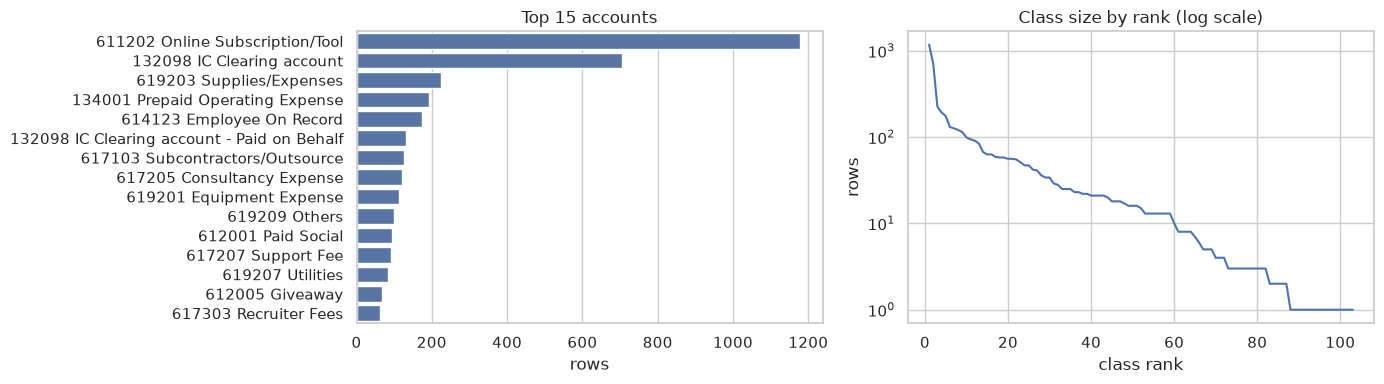

In [3]:
counts = df["accountName"].value_counts()

print(f"top-1 class: {counts.iloc[0] / len(df):.1%} of rows | top-5: {counts.head(5).sum() / len(df):.1%}")
print(f"classes with <5 rows: {(counts < 5).sum()} | singletons: {(counts == 1).sum()}")

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.barplot(x=counts.head(15).values, y=counts.head(15).index, ax=ax[0])
ax[0].set(title="Top 15 accounts", xlabel="rows", ylabel="")
sns.lineplot(x=range(1, len(counts) + 1), y=counts.values, ax=ax[1])
ax[1].set(yscale="log", title="Class size by rank (log scale)", xlabel="class rank", ylabel="rows")
plt.tight_layout()
plt.show()

**Takeaway:** heavy long tail. 5 accounts hold half the data; 34 accounts have <5 rows.
Accuracy is driven by big classes; macro-F1 will show how badly the small ones do.

## 3. Item name: bill-month prefix

Most names start with `MMYY`, e.g. `0825 Zoom ...` = bill for Aug 2025.

names with a valid month prefix: 86.7%
itemName == itemDescription: 83.1%


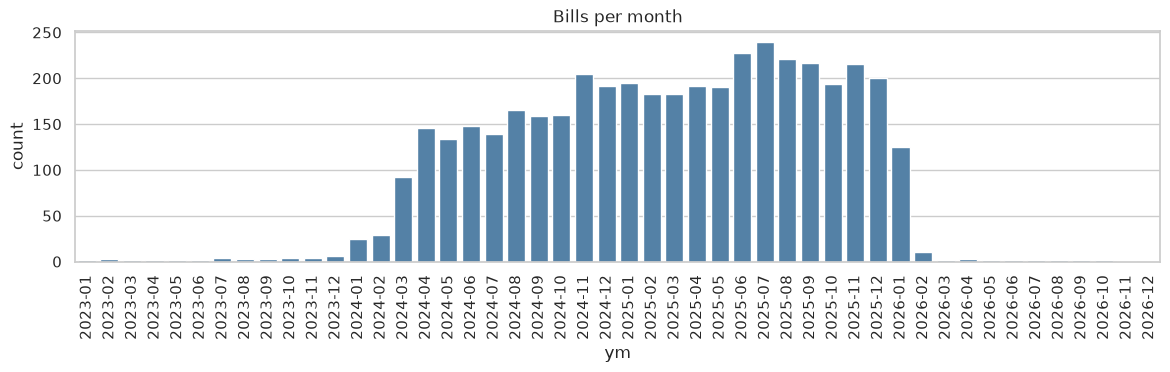

In [4]:
prefix = df["itemName"].str.extract(r"^(\d{2})(\d{2})\b")
ok = pd.to_numeric(prefix[0], errors="coerce").between(1, 12) & prefix[1].isin(["23", "24", "25", "26"])
df["ym"] = np.where(ok, "20" + prefix[1] + "-" + prefix[0], None)

print(f"names with a valid month prefix: {df['ym'].notna().mean():.1%}")
print(f"itemName == itemDescription: {(df['itemName'] == df['itemDescription']).mean():.1%}")

plt.figure(figsize=(14, 3))
sns.countplot(x="ym", data=df, order=sorted(df["ym"].dropna().unique()), color="steelblue")
plt.title("Bills per month")
plt.xticks(rotation=90)
plt.show()

**Takeaway:** the prefix is a date, not meaning — remove it from the text, but use it to build a future-months test set.
Description is a copy of the name 83% of the time, so it adds little.

## 4. Recurring bills

Strip the prefix and numbers: how many bills are the same line repeated every month?

In [5]:
df["norm"] = (df["itemName"].str.lower()
              .str.replace(r"^\d{4}\s*[-_]?\s*", "", regex=True)  # drop month prefix
              .str.replace(r"\d+", "#", regex=True)                  # numbers -> #
              .str.strip())

repeat = df["norm"].map(df["norm"].value_counts()) > 1
print(f"distinct names: {df['itemName'].nunique()} -> after cleaning: {df['norm'].nunique()}")
print(f"rows that are a repeat of another line: {repeat.mean():.1%}")

df[df["norm"] == "crs"][["itemName", "accountName"]].head(6)

distinct names: 4060 -> after cleaning: 2169
rows that are a repeat of another line: 69.0%


,itemName,accountName
2354,0424 CRS,614304 Insurance expenses
2355,0524 CRS,614304 Insurance expenses
2356,0624 CRS,134001 Prepaid Operating Expense
2362,0424 CRS,614304 Insurance expenses
2995,0724 CRS,614304 Insurance expenses
2996,0824 CRS,614304 Insurance expenses


**Takeaway:** 69% of rows are monthly repeats. A random train/test split puts the same line on both sides,
so validation scores look better than they really are. The future-months test set avoids this.

## 5. Vendor

How much does the vendor alone tell us?

vendors always using 1 account: 211 of 337
accuracy of 'predict vendor's usual account': 73.9%


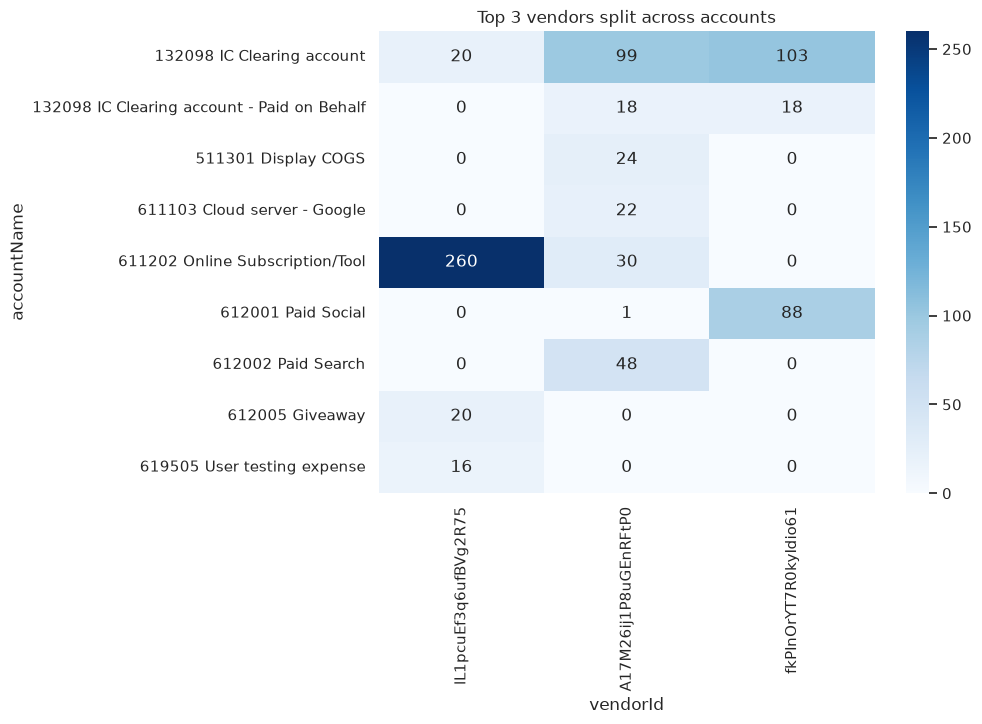

In [6]:
per_vendor = df.groupby("vendorId")["accountName"]
top_share = per_vendor.agg(lambda s: s.value_counts().iloc[0])  # rows in vendor's most common account

print(f"vendors always using 1 account: {(per_vendor.nunique() == 1).sum()} of {df['vendorId'].nunique()}")
print(f"accuracy of 'predict vendor's usual account': {top_share.sum() / len(df):.1%}")

# Top 3 vendors: which accounts do their bills go to?
big = df["vendorId"].value_counts().head(3).index
table = pd.crosstab(df["accountName"], df["vendorId"])[big]
table = table[table.sum(axis=1) > 15]

plt.figure(figsize=(8, 6))
sns.heatmap(table, annot=True, fmt="d", cmap="Blues")
plt.title("Top 3 vendors split across accounts")
plt.show()

**Takeaway:** vendor alone gets ~74%. The biggest vendors (ad platforms, SaaS) split across several accounts,
so the item text is needed to tell them apart.

## 6. Amount

count         4894.0
mean         92666.9
std        3037294.5
min         -15195.0
25%            155.0
50%            845.2
75%           3507.1
max      161838000.0

negative (refunds): 19 | above 1M: 7


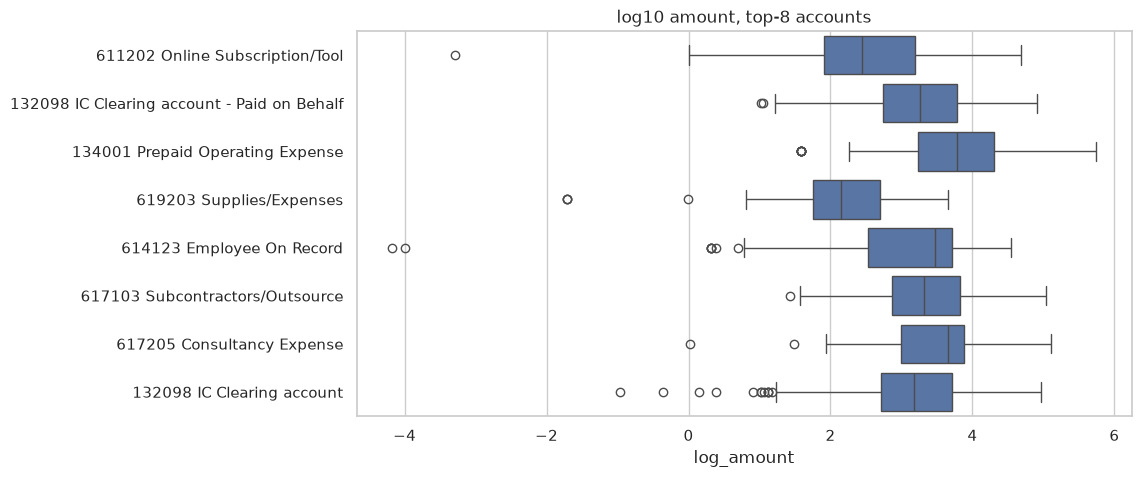

In [7]:
amount = df["itemTotalAmount"]
print(amount.describe().round(1).to_string())
print("\nnegative (refunds):", (amount < 0).sum(), "| above 1M:", (amount > 1e6).sum())

df["log_amount"] = np.sign(amount) * np.log10(1 + amount.abs())
top8 = df[df["accountName"].isin(counts.head(8).index)]

plt.figure(figsize=(10, 5))
sns.boxplot(x="log_amount", y="accountName", data=top8)
plt.title("log10 amount, top-8 accounts")
plt.ylabel("")
plt.show()

**Takeaway:** median 845 but max 161M — needs a log scale. Amounts overlap a lot between accounts,
so amount is a weak, secondary feature.

## 7. Label quality: renamed accounts

97 IDs but 103 names, so some IDs carry two names. When did each name appear?

In [8]:
names_per_id = df.groupby("accountId")["accountName"].nunique()
renamed = df[df["accountId"].isin(names_per_id[names_per_id > 1].index)]

renamed.groupby(["accountId", "accountName"])["ym"].agg(["min", "max", "size"])

min  \
accountId            accountName                                            
6yL6YRA4Rkj2gUD4RAO0 230051 Lease payable                         2024-04   
                     232101 Lease payable                         2024-11   
AS7kZeVZgNNPi7UQOSKD 222003 Customer Prepayment                   2024-09   
                     231101 Customer Prepayment                   2024-12   
lXfE1brSF0STqngL58cZ 612039 Marketing Research                    2025-01   
                     617213 Marketing Research                    2024-03   
riKWPz2LlaISic7O9pvu 614336 Employee Training                     2024-09   
                     614400 Employee Training                     2024-06   
w5hjK0IooxdDp9Feeeuy 132098 IC Clearing account                   2023-07   
                     132098 IC Clearing account - Paid on Behalf  2025-06   
xHRgcOAxvnyVodNsjdah 151101 Cost                                  2024-04   
                     151101 Trademarks - Cost                     2024-10   

                                                                      max  \
accountId            accountName                                            
6yL6YRA4Rkj2gUD4RAO0 230051 Lease payable                         2024-11   
                     232101 Lease payable                         2025-12   
AS7kZeVZgNNPi7UQOSKD 222003 Customer Prepayment                   2024-09   
                     231101 Customer Prepayment                   2026-01   
lXfE1brSF0STqngL58cZ 612039 Marketing Research                    2025-01   
                     617213 Marketing Research                    2024-03   
riKWPz2LlaISic7O9pvu 614336 Employee Training                     2025-11   
                     614400 Employee Training                     2024-10   
w5hjK0IooxdDp9Feeeuy 132098 IC Clearing account                   2025-09   
                     132098 IC Clearing account - Paid on Behalf  2026-01   
xHRgcOAxvnyVodNsjdah 151101 Cost                                  2024-09   
                     151101 Trademarks - Cost                     2025-10   

                                                                  size  
accountId            accountName                                        
6yL6YRA4Rkj2gUD4RAO0 230051 Lease payable                           15  
                     232101 Lease payable                           29  
AS7kZeVZgNNPi7UQOSKD 222003 Customer Prepayment                      2  
                     231101 Customer Prepayment                     16  
lXfE1brSF0STqngL58cZ 612039 Marketing Research                       1  
                     617213 Marketing Research                       1  
riKWPz2LlaISic7O9pvu 614336 Employee Training                        8  
                     614400 Employee Training                        8  
w5hjK0IooxdDp9Feeeuy 132098 IC Clearing account                    706  
                     132098 IC Clearing account - Paid on Behalf   131  
xHRgcOAxvnyVodNsjdah 151101 Cost                                    17  
                     151101 Trademarks - Cost                       25

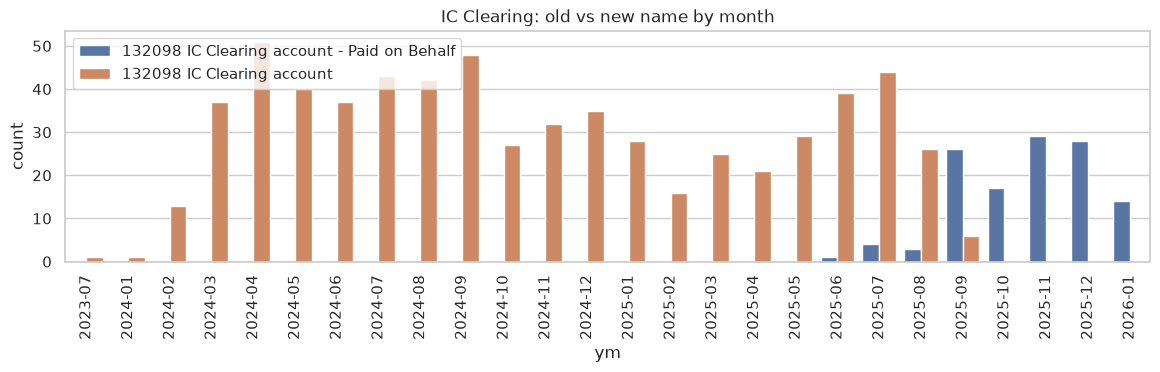

In [9]:
ic = df[df["accountName"].str.startswith("132098") & df["ym"].notna()]

plt.figure(figsize=(14, 3))
sns.countplot(x="ym", hue="accountName", data=ic, order=sorted(ic["ym"].unique()))
plt.title("IC Clearing: old vs new name by month")
plt.legend(loc="upper left")
plt.xticks(rotation=90)
plt.show()

**Takeaway:** 6 accounts were renamed over time. Biggest one: `IC Clearing account` became
`IC Clearing account - Paid on Behalf` around Sep 2025. Same bills, new label —
a model trained on older months will keep predicting the old name.

## 8. Prepaid vs Online Subscription

These two get confused a lot. Prepaid bills often cover a period like `0126-1226`.

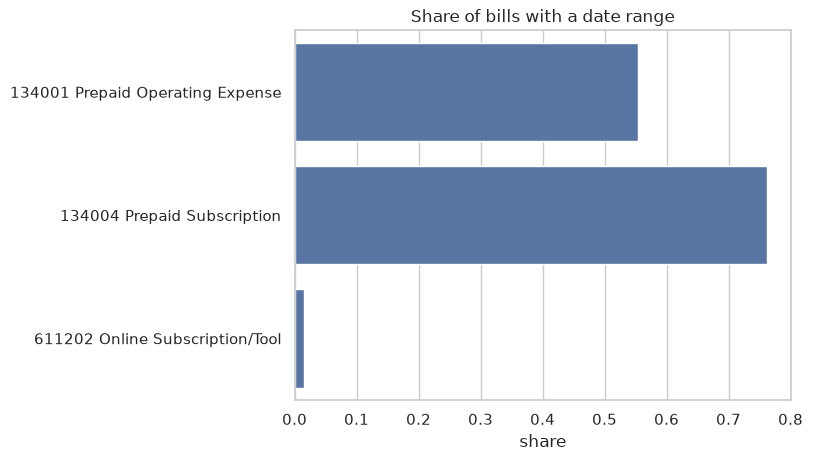

In [10]:
df["has_range"] = df["itemName"].str.contains(r"^\s*\d{4}\s*[-–]\s*\d{4}\b").astype(int)

pair = ["611202 Online Subscription/Tool", "134001 Prepaid Operating Expense", "134004 Prepaid Subscription"]
share = df[df["accountName"].isin(pair)].groupby("accountName")["has_range"].mean()

sns.barplot(x=share.values, y=share.index)
plt.title("Share of bills with a date range")
plt.xlabel("share")
plt.ylabel("")
plt.show()

**Takeaway:** over half of prepaid bills have a date range vs ~1% of subscriptions — a useful feature.

## Summary → modelling decisions

1. Strip the month prefix and numbers from text; keep the month for a future-months test set.
2. Use TF-IDF on text + vendor one-hot + log amount.
3. Expect high accuracy on big classes, weak on the 34 tiny ones — report macro-F1 too.
4. Renamed accounts will cost accuracy on future months — call it out as a known limitation.